## Modelo 3: EEGNet-style, 2 canales, configuración V2

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, accuracy_score, f1_score,
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

In [2]:
import os, numpy as np

NPZ_PATH = os.path.expanduser("~/Desktop/TFM/datos_procesados/datos_procesados_2canales.npz")
data = np.load(NPZ_PATH)

X_train_norm, y_train = data["X_train_norm"], data["y_train"]
X_val_norm,   y_val   = data["X_val_norm"],   data["y_val"]
X_test_norm,  y_test  = data["X_test_norm"],  data["y_test"]

print("Train:", X_train_norm.shape, "| Val:", X_val_norm.shape, "| Test:", X_test_norm.shape)

n_samples = X_train_norm.shape[1]    # 3000
n_channels = X_train_norm.shape[2]   # 2
print(n_samples, n_channels)

Train: (50005, 3000, 2) | Val: (11534, 3000, 2) | Test: (12390, 3000, 2)
3000 2


## Modelo: EEGNet-style simplificado

In [3]:
def build_eegnet_style(n_samples, n_channels, F1=16, D=2, F2=32,
                        kernel_temporal=50, kernel_separable=16, dropout_rate=0.3):
    inputs = layers.Input(shape=(n_samples, n_channels))

    x = layers.Permute((2, 1))(inputs)
    x = layers.Reshape((n_channels, n_samples, 1))(x)

    x = layers.Conv2D(F1, kernel_size=(1, kernel_temporal),
                       padding="same", use_bias=False)(x)

    x = layers.DepthwiseConv2D(kernel_size=(n_channels, 1), depth_multiplier=D,
                                use_bias=False,
                                depthwise_constraint=tf.keras.constraints.max_norm(1.))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.AveragePooling2D((1, 4))(x)
    x = layers.Dropout(dropout_rate)(x)

    new_len = x.shape[2]
    x = layers.Reshape((new_len, F1 * D))(x)

    x = layers.SeparableConv1D(F2, kernel_size=kernel_separable,
                                padding="same", use_bias=False)(x)
    x = layers.Activation("relu")(x)
    x = layers.AveragePooling1D(4)(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.GlobalAveragePooling1D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = models.Model(inputs, outputs, name="EEGNet_style")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_eegnet = build_eegnet_style(n_samples, n_channels)
model_eegnet.summary()

Model: "EEGNet_style"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3000, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 2, 3000)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 2, 3000, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 2, 3000, 16)    │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 1, 3000, 32)    │            64 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1, 3000, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 3000, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 750, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 750, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv1d                │ (None, 750, 32)        │         1,536 │
│ (SeparableConv1D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d               │ (None, 187, 32)        │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 187, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 64 (256.00 B)

## Entrenamiento — Configuración V2

In [5]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    "modelo3_eegnet_2canales_v2.keras",
    monitor="val_loss",
    save_best_only=True,
)

history_eegnet = model_eegnet.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=100,
    batch_size=64,
    class_weight={0: 1.0, 1: (y_train == 0).sum() / max((y_train == 1).sum(), 1)},
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 66s 82ms/step - accuracy: 0.9382 - loss: 0.1588 - val_accuracy: 0.9577 - val_loss: 0.1054
Epoch 2/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 63s 81ms/step - accuracy: 0.9689 - loss: 0.0882 - val_accuracy: 0.9676 - val_loss: 0.0852
Epoch 3/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 63s 81ms/step - accuracy: 0.9703 - loss: 0.0835 - val_accuracy: 0.9626 - val_loss: 0.0976
Epoch 4/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 82ms/step - accuracy: 0.9739 - loss: 0.0768 - val_accuracy: 0.9710 - val_loss: 0.0754
Epoch 5/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 63s 81ms/step - accuracy: 0.9764 - loss: 0.0714 - val_accuracy: 0.9730 - val_loss: 0.0738
Epoch 6/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 81ms/step - accuracy: 0.9766 - loss: 0.0672 - val_accuracy: 0.9728 - val_loss: 0.0773
Epoch 7/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 81ms/step - accuracy: 0.9774 - loss: 0.0637 - val_accuracy: 0.9728 - val_loss: 0.0763
Epoch 8/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 82ms/step - accuracy: 0.9792 - loss: 0

In [7]:
import os, json

RUN_DIR = os.path.expanduser("~/Desktop/TFM/EEGNet/EEGNet_2canales_V2")
os.makedirs(RUN_DIR, exist_ok=True)

# Guarda el modelo y el historial
model_eegnet.save(os.path.join(RUN_DIR, "modelo_eegnet_2canales_v2.keras"))
with open(os.path.join(RUN_DIR, "historial_entrenamiento.json"), "w") as f:
    json.dump(history_eegnet.history, f)

In [8]:
import json
with open(os.path.join(RUN_DIR, "historial_entrenamiento.json")) as f:
    hist_dict = json.load(f)

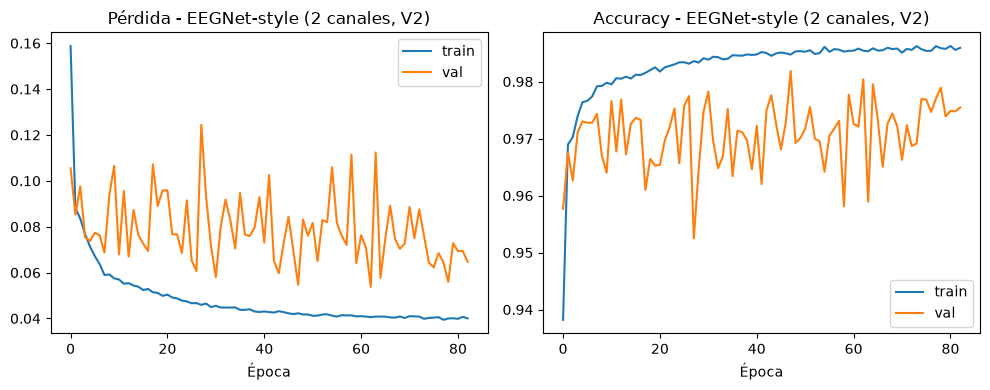

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_eegnet.history["loss"], label="train")
plt.plot(history_eegnet.history["val_loss"], label="val")
plt.title("Pérdida - EEGNet-style (2 canales, V2)")
plt.xlabel("Época")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_eegnet.history["accuracy"], label="train")
plt.plot(history_eegnet.history["val_accuracy"], label="val")
plt.title("Accuracy - EEGNet-style (2 canales, V2)")
plt.xlabel("Época")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "curvas_entrenamiento.png"), dpi=300, bbox_inches="tight")
plt.show()

## Evaluación en el conjunto de test

388/388 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step
              precision    recall  f1-score   support

     Vigilia      0.976     0.973     0.974      6913
       Sueño      0.966     0.969     0.968      5477

    accuracy                          0.971     12390
   macro avg      0.971     0.971     0.971     12390
weighted avg      0.971     0.971     0.971     12390

ROC-AUC: 0.996


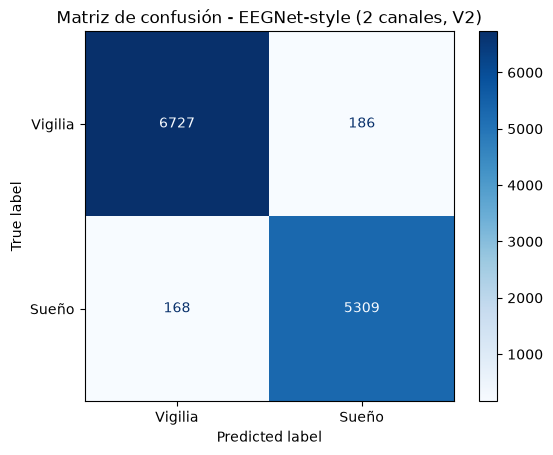

In [10]:
y_pred_prob_eegnet = model_eegnet.predict(X_test_norm).ravel()
y_pred_eegnet = (y_pred_prob_eegnet >= 0.5).astype(int)

print(classification_report(y_test, y_pred_eegnet, target_names=["Vigilia", "Sueño"], digits=3))

roc_auc_eegnet = roc_auc_score(y_test, y_pred_prob_eegnet)
print(f"ROC-AUC: {roc_auc_eegnet:.3f}")

cm_eegnet = confusion_matrix(y_test, y_pred_eegnet)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_eegnet, display_labels=["Vigilia", "Sueño"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - EEGNet-style (2 canales, V2)")
plt.savefig(os.path.join(RUN_DIR, "matriz_confusion.png"), dpi=300, bbox_inches="tight")
plt.show()

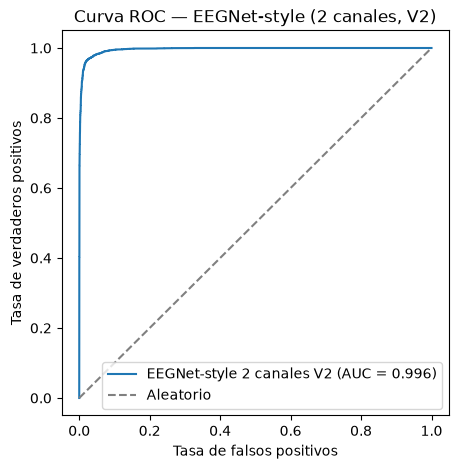

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob_eegnet)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"EEGNet-style 2 canales V2 (AUC = {roc_auc_eegnet:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — EEGNet-style (2 canales, V2)")
plt.legend()
plt.savefig(os.path.join(RUN_DIR, "roc_curve.png"), dpi=300, bbox_inches="tight")
plt.show()